In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Imports and Environment setup

In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, cohen_kappa_score, roc_curve
)

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, Conv1D, MaxPooling1D,
    Bidirectional, LSTM, Dense, Dropout, GlobalMaxPooling1D
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping


# Load Cleaned Dataset

In [3]:
DATA_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Data/Assamese_Movie_Review_Cleaned_8987.csv"

df = pd.read_csv(DATA_PATH)
df.head()


,ID,Reviews,Sentiment
0,0,বোকা নাটক,negative
1,1,নাটকখন বৰ ধুনীয়া আছিল,positive
2,2,এখন ভাল ঘৰ এনে হব লাগে,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive
4,4,মই বহুদিন অপেক্ষা কৰি আছো. অৱশেষত দেখিলো. কেৱল...,positive


In [4]:
# Remove corrupted row with header leakage
df = df[~((df['ID'] == 4227) & (df['Reviews'] == 'Reviews'))].reset_index(drop=True)

print("Dataset shape after removing corrupted row:", df.shape)


Dataset shape after removing corrupted row: (8986, 3)


In [5]:
assert not ((df['Reviews'] == 'Reviews') | (df['Sentiment'].isna())).any(), \
    "Corrupted rows still exist in the dataset"


In [6]:
df['Sentiment'] = (
    df['Sentiment']
    .astype(str)
    .str.strip()
    .str.lower()
)


# Label Encoding

In [7]:
label_encoder = LabelEncoder()
df['label'] = label_encoder.fit_transform(df['Sentiment'])

# positive → 1, negative → 0
df[['Sentiment', 'label']].drop_duplicates()


,Sentiment,label
0,negative,0
1,positive,1


# Train-Test-Validation Split

In [8]:
X_train, X_val, y_train, y_val = train_test_split(
    df['Reviews'],
    df['label'],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)
len(X_train), len(X_val)

(7188, 1798)

#  Tokenization (Keras Tokenizer)

In [11]:
MAX_VOCAB_SIZE = 50000
MAX_SEQUENCE_LENGTH = 200

tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(X_train.astype(str))

X_train_seq = tokenizer.texts_to_sequences(X_train.astype(str))
X_val_seq   = tokenizer.texts_to_sequences(X_val.astype(str))

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding='post',
    truncating='post'
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding='post',
    truncating='post'
)

# CNN-BiLSTM Architecture

CNN → local n-gram sentiment cues

BiLSTM → long-range Assamese context

Global pooling → parameter efficiency

In [12]:
EMBEDDING_DIM = 300

input_layer = Input(shape=(MAX_SEQUENCE_LENGTH,))

embedding_layer = Embedding(
    input_dim=MAX_VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    input_length=MAX_SEQUENCE_LENGTH,
    trainable=True
)(input_layer)

cnn_layer = Conv1D(
    filters=128,
    kernel_size=5,
    activation='relu'
)(embedding_layer)

cnn_pool = MaxPooling1D(pool_size=2)(cnn_layer)

bilstm_layer = Bidirectional(
    LSTM(128, return_sequences=True)
)(cnn_pool)

global_pool = GlobalMaxPooling1D()(bilstm_layer)

dense_layer = Dense(128, activation='relu')(global_pool)
dropout = Dropout(0.5)(dense_layer)

output_layer = Dense(1, activation='sigmoid')(dropout)

model = Model(inputs=input_layer, outputs=output_layer)

model.compile(
    loss='binary_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4),
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 200, 300)       │    15,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 196, 128)       │       192,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 98, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 98, 256)        │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 256)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,488,321 (59.08 MB)

 Trainable params: 15,488,321 (59.08 MB)

 Non-trainable params: 0 (0.00 B)

# Training

In [13]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.6308 - loss: 0.6591 - val_accuracy: 0.5439 - val_loss: 0.6971
Epoch 2/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.7155 - loss: 0.5099 - val_accuracy: 0.8971 - val_loss: 0.2642
Epoch 3/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.9351 - loss: 0.1770 - val_accuracy: 0.9266 - val_loss: 0.2108
Epoch 4/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.9749 - loss: 0.0880 - val_accuracy: 0.9305 - val_loss: 0.1973
Epoch 5/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.9872 - loss: 0.0490 - val_accuracy: 0.9333 - val_loss: 0.2134
Epoch 6/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.9905 - loss: 0.0326 - val_accuracy: 0.9377 - val_loss: 0.2242
Epoch 7/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.9944 - loss: 0.0286 - val_accuracy: 0.9410 - val_loss: 0.2256


# Training vs Validation Loss Curves

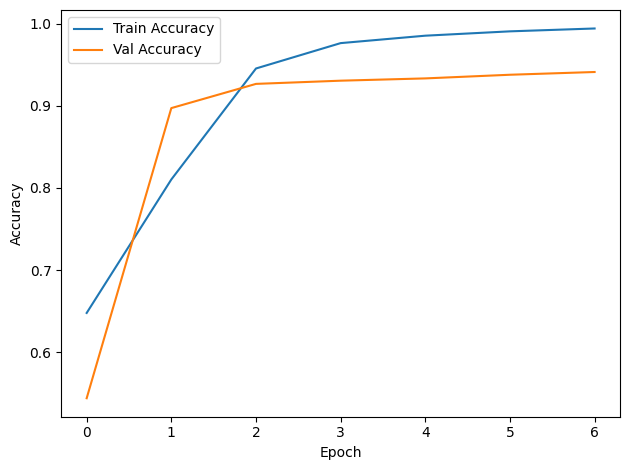

In [14]:
RESULTS_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/"
os.makedirs(RESULTS_PATH, exist_ok=True)

plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()

plt.savefig(f"{RESULTS_PATH}cnn_bilstm_training_validation.svg", format="svg")
plt.show()


# Evaluation Metrics

In [15]:
y_val_probs = model.predict(X_val_pad).ravel()
y_val_preds = (y_val_probs >= 0.5).astype(int)

metrics = {
    "accuracy": accuracy_score(y_val, y_val_preds),
    "macro_f1": f1_score(y_val, y_val_preds, average='macro'),
    "macro_precision": precision_score(y_val, y_val_preds, average='macro'),
    "macro_recall": recall_score(y_val, y_val_preds, average='macro'),
    "roc_auc": roc_auc_score(y_val, y_val_probs),
    "cohen_kappa": cohen_kappa_score(y_val, y_val_preds)
}

metrics


57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


{'accuracy': 0.9304783092324805,
 'macro_f1': 0.9237803585629673,
 'macro_precision': 0.9341430920710256,
 'macro_recall': 0.9159889472788392,
 'roc_auc': np.float64(0.9786658014552572),
 'cohen_kappa': np.float64(0.8477404616766637)}

# Confusion Matrix

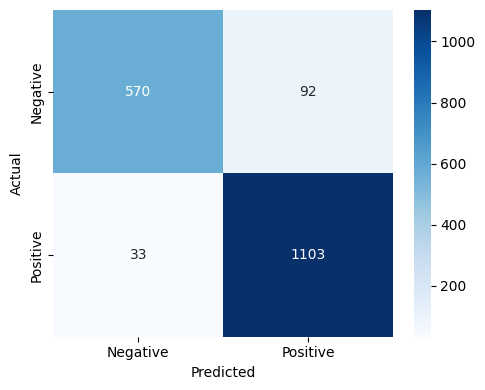

In [16]:
CM_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/Confusion Matrix/"
os.makedirs(CM_PATH, exist_ok=True)

cm = confusion_matrix(y_val, y_val_preds)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()

plt.savefig(f"{CM_PATH}cnn_bilstm_confusion_matrix.svg", format="svg")
plt.show()


# Save Model & Tokenizer

In [18]:
MODEL_SAVE_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Models/CNN_BiLSTM/"
os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

# Save model in native Keras format
model.save(f"{MODEL_SAVE_PATH}cnn_bilstm_model.keras")

# Save tokenizer
import pickle
with open(f"{MODEL_SAVE_PATH}tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("CNN–BiLSTM model and tokenizer saved successfully.")


CNN–BiLSTM model and tokenizer saved successfully.
